# Visualisation du dataset HandX

Ce notebook charge quelques séquences HandX, affiche leurs articulations en 3D puis anime le squelette et les surfaces MANO.

In [1]:
from pathlib import Path
import sys

import matplotlib.pyplot as plt
import numpy as np
import torch
from IPython.display import HTML, display

PROJECT_ROOT = next(
    path for path in (Path.cwd(), *Path.cwd().parents)
    if (path / "data" / "handx_loader.py").is_file()
)
if str(PROJECT_ROOT) not in sys.path:
    sys.path.insert(0, str(PROJECT_ROOT))

from data import Mano3DPlot, get_handx_loader

try:
    import ipympl
    get_ipython().run_line_magic("matplotlib", "widget")
    INTERACTIVE_3D = True
except ImportError:
    get_ipython().run_line_magic("matplotlib", "inline")
    INTERACTIVE_3D = False
    print("Installer ipympl pour manipuler la vue 3D avec la souris.")

In [2]:
BATCH_SIZE = 4
SAMPLE_ID = 0
SEED = 0

torch.manual_seed(SEED)
loader = get_handx_loader(
    batch_size=BATCH_SIZE,
    shuffle=True,
    train=False,
    include_mano=True,
    use_paraphrases=False,
    text_mode="combined",
)
batch = next(iter(loader))

print(len(loader.dataset), "séquences de test")
for index in range(len(batch["text"])):
    print(f"[{index}] source={batch['source'][index]} clé={batch['key'][index]}")
    print(batch["text"][index])
    print()

9648 séquences de test
[0] source=HoloAssist clé=2298
Left hand: The index fingertip makes contact with the thumb tip twice at the start, while the ring and pinky fingers perform a bending motion. Right hand: The index finger makes contact with the thumb early on. Towards the end, the pinky finger's base joint moves into hyperextension. Interaction: Mid-sequence, the left ring and pinky fingertips make contact with the right thumb tip.

[1] source=HoloAssist clé=5599
Left hand: The ring and pinky fingers perform fast bending motions at the start, while the other fingers remain static. The wrist moves down. Right hand: The middle and ring fingers bend and straighten. The thumb repeatedly makes contact with the ring and pinky fingertips. Interaction: The two thumbs briefly make contact at the beginning of the sequence.

[2] source=HandX clé=5631
Left hand: The fingers slowly bend from an open to a closed posture, with the pinky initially hyperextended at its base. Right hand: The fingers

## Quelques samples en 3D

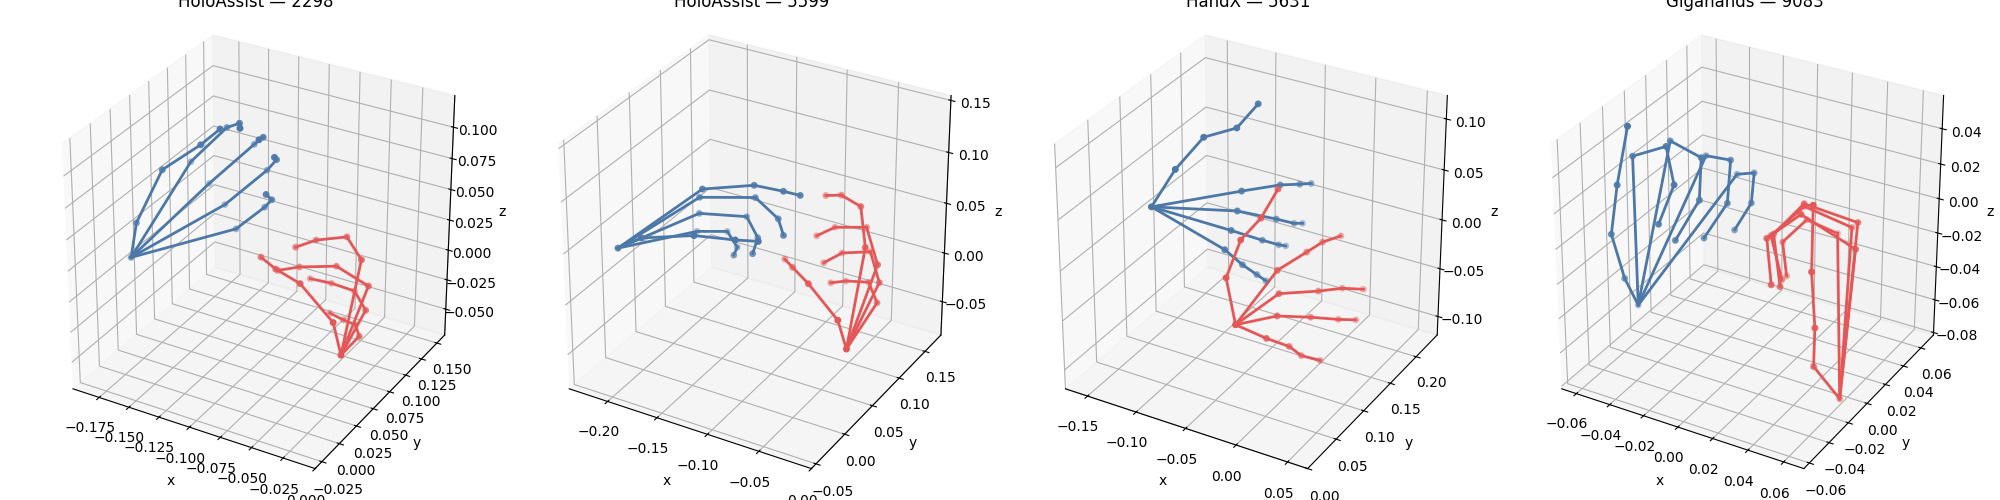

In [3]:
visualizer = Mano3DPlot(fps=20)
figure = plt.figure(figsize=(5 * BATCH_SIZE, 5))

for sample_id in range(BATCH_SIZE):
    axis = figure.add_subplot(1, BATCH_SIZE, sample_id + 1, projection="3d")
    frame = batch["motion"][sample_id, 0].numpy()

    for hand_id, color in ((0, visualizer.left_color), (1, visualizer.right_color)):
        joints = frame[hand_id]
        axis.scatter(joints[:, 0], joints[:, 1], joints[:, 2], color=color, s=16)
        for start, end in visualizer.hand_edges:
            segment = joints[[start, end]]
            axis.plot(segment[:, 0], segment[:, 1], segment[:, 2], color=color, linewidth=2)

    minimum = frame.reshape(-1, 3).min(axis=0)
    maximum = frame.reshape(-1, 3).max(axis=0)
    center = (minimum + maximum) / 2
    radius = max((maximum - minimum).max() / 2, 1e-3)
    axis.set_xlim(center[0] - radius, center[0] + radius)
    axis.set_ylim(center[1] - radius, center[1] + radius)
    axis.set_zlim(center[2] - radius, center[2] + radius)
    axis.set_box_aspect((1, 1, 1))
    axis.set_title(f"{batch['source'][sample_id]} — {batch['key'][sample_id]}")
    axis.set_xlabel("x")
    axis.set_ylabel("y")
    axis.set_zlabel("z")

plt.tight_layout()
plt.show()

In [4]:
motion = batch["motion"][SAMPLE_ID]
title = batch["interaction_text"][SAMPLE_ID]

print(title)
print(motion.shape)

Mid-sequence, the left ring and pinky fingertips make contact with the right thumb tip.
torch.Size([60, 2, 21, 3])


## Mouvement des articulations

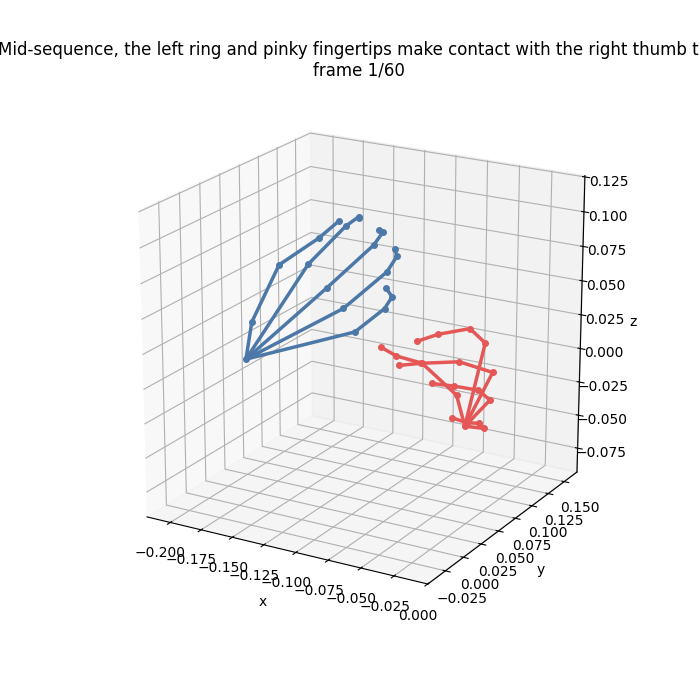

In [5]:
joint_animation = visualizer.animate_hands(
    left_joints=motion[:, 0],
    right_joints=motion[:, 1],
    title=title,
    max_frames=None,
)

if INTERACTIVE_3D:
    plt.show()
else:
    plt.close(joint_animation._fig)
    display(HTML(joint_animation.to_jshtml(fps=visualizer.fps)))

## Mouvement des surfaces MANO

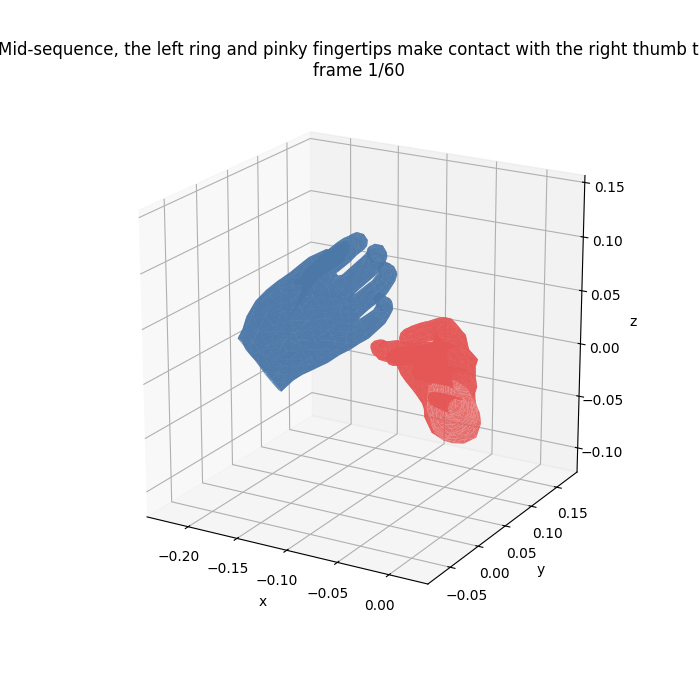

In [6]:
mano_animation = visualizer.animate_handx_mano_hands(
    left_pose=batch["left_pose"][SAMPLE_ID],
    left_betas=batch["left_shape"][SAMPLE_ID],
    left_trans=batch["left_trans"][SAMPLE_ID],
    right_pose=batch["right_pose"][SAMPLE_ID],
    right_betas=batch["right_shape"][SAMPLE_ID],
    right_trans=batch["right_trans"][SAMPLE_ID],
    left_joints=motion[:, 0],
    right_joints=motion[:, 1],
    show_joints=False,
    title=title,
    max_frames=None,
)

if INTERACTIVE_3D:
    plt.show()
else:
    plt.close(mano_animation._fig)
    display(HTML(mano_animation.to_jshtml(fps=visualizer.fps)))